# Update 2 — RQ2 Identity Trajectory

This notebook measures how Human and LLM source identity changes from T0 to T3. The split is performed at the `group_id` level so paraphrase variants from one source cannot appear in both train and test data. PCA is the primary projection; t-SNE is included as an exploratory visualization.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / 'data/processed/update2_features.pkl'
RESULTS_DIR = PROJECT_ROOT / 'data/results/update2'
FIGURES_DIR = PROJECT_ROOT / 'figures/update2'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

from src.identity_trajectory import (
    aggregate_group_stage,
    fit_pca_projection,
    fit_tsne_projection,
    make_group_split,
    plot_pca_trajectory,
    plot_tsne_trajectory,
    sample_balanced,
    summarize_separation,
    validate_feature_frame,
)

In [2]:
features = pd.read_pickle(DATA_PATH)
validate_feature_frame(features)
print(f'Feature rows: {len(features):,}')
print(f'Groups: {features.group_id.nunique():,}')
print(f'Datasets: {features.dataset.nunique()}')
display(features[['dataset', 'source_group', 'stage']].drop_duplicates().sort_values(['dataset', 'source_group', 'stage']).head(14))

Feature rows: 530,636
Groups: 3,020
Datasets: 7


,dataset,source_group,stage
8,cmv,Human,t0
132667,cmv,Human,t1
265326,cmv,Human,t2
397985,cmv,Human,t3
0,cmv,LLM,t0
132659,cmv,LLM,t1
265318,cmv,LLM,t2
397977,cmv,LLM,t3
1605,eli5,Human,t0
134264,eli5,Human,t1


## Group-level split and aggregation

The split is stratified by dataset, but the unit of splitting is `group_id`. Features are then averaged within dataset, group, source type, and stage.

In [3]:
train_ids, test_ids, split = make_group_split(features, random_state=42)
assert train_ids.isdisjoint(test_ids)
split.to_csv(RESULTS_DIR / 'rq2_identity_group_split.csv', index=False)
aggregated = aggregate_group_stage(features)
pca_embeddings, imputer, scaler, pca = fit_pca_projection(aggregated, train_group_ids=train_ids, random_state=42)
print(f'Train groups: {len(train_ids):,}; test groups: {len(test_ids):,}')
print(f'Aggregated rows: {len(aggregated):,}')
print('PCA explained variance:', [round(float(x), 4) for x in pca.explained_variance_ratio_])

Train groups: 2,416; test groups: 604
Aggregated rows: 24,160
PCA explained variance: [0.2445, 0.0991]


In [4]:
tsne_sample = sample_balanced(aggregated, train_ids, per_cell=50, random_state=42)
tsne_embeddings = fit_tsne_projection(tsne_sample, aggregated, imputer, scaler, random_state=42)
separation = summarize_separation(pca_embeddings, ['pca1', 'pca2'])
pca_embeddings.to_csv(RESULTS_DIR / 'rq2_pca_embeddings.csv', index=False)
tsne_embeddings.to_csv(RESULTS_DIR / 'rq2_tsne_embeddings.csv', index=False)
separation.to_csv(RESULTS_DIR / 'rq2_identity_separation.csv', index=False)
summary = {
    'n_feature_rows': int(len(features)),
    'n_aggregated_rows': int(len(aggregated)),
    'n_groups': int(aggregated.group_id.nunique()),
    'n_train_groups': int(len(train_ids)),
    'n_test_groups': int(len(test_ids)),
    'feature_count': int(len(pca.feature_names_in_)) if hasattr(pca, 'feature_names_in_') else 23,
    'pca_explained_variance_ratio': pca.explained_variance_ratio_.tolist(),
    'tsne_sample_rows': int(len(tsne_embeddings)),
    'random_state': 42,
}
(RESULTS_DIR / 'rq2_identity_trajectory_summary.json').write_text(json.dumps(summary, indent=2))
plot_pca_trajectory(pca_embeddings, FIGURES_DIR / 'rq2_pca_identity_trajectory.png')
plot_tsne_trajectory(tsne_embeddings, FIGURES_DIR / 'rq2_tsne_identity_trajectory.png')
display(separation.round(4))

,stage,n_datasets,centroid_distance,human_pca1,human_pca2,llm_pca1,llm_pca2
0,t0,7,0.2752,0.0515,-0.0414,-0.0082,-0.3101
1,t1,7,0.1456,0.0222,-0.0624,-0.0472,-0.1904
2,t2,7,0.1421,-0.0397,0.0133,-0.1261,-0.0995
3,t3,7,0.1392,-0.1057,0.1106,-0.1757,-0.0097


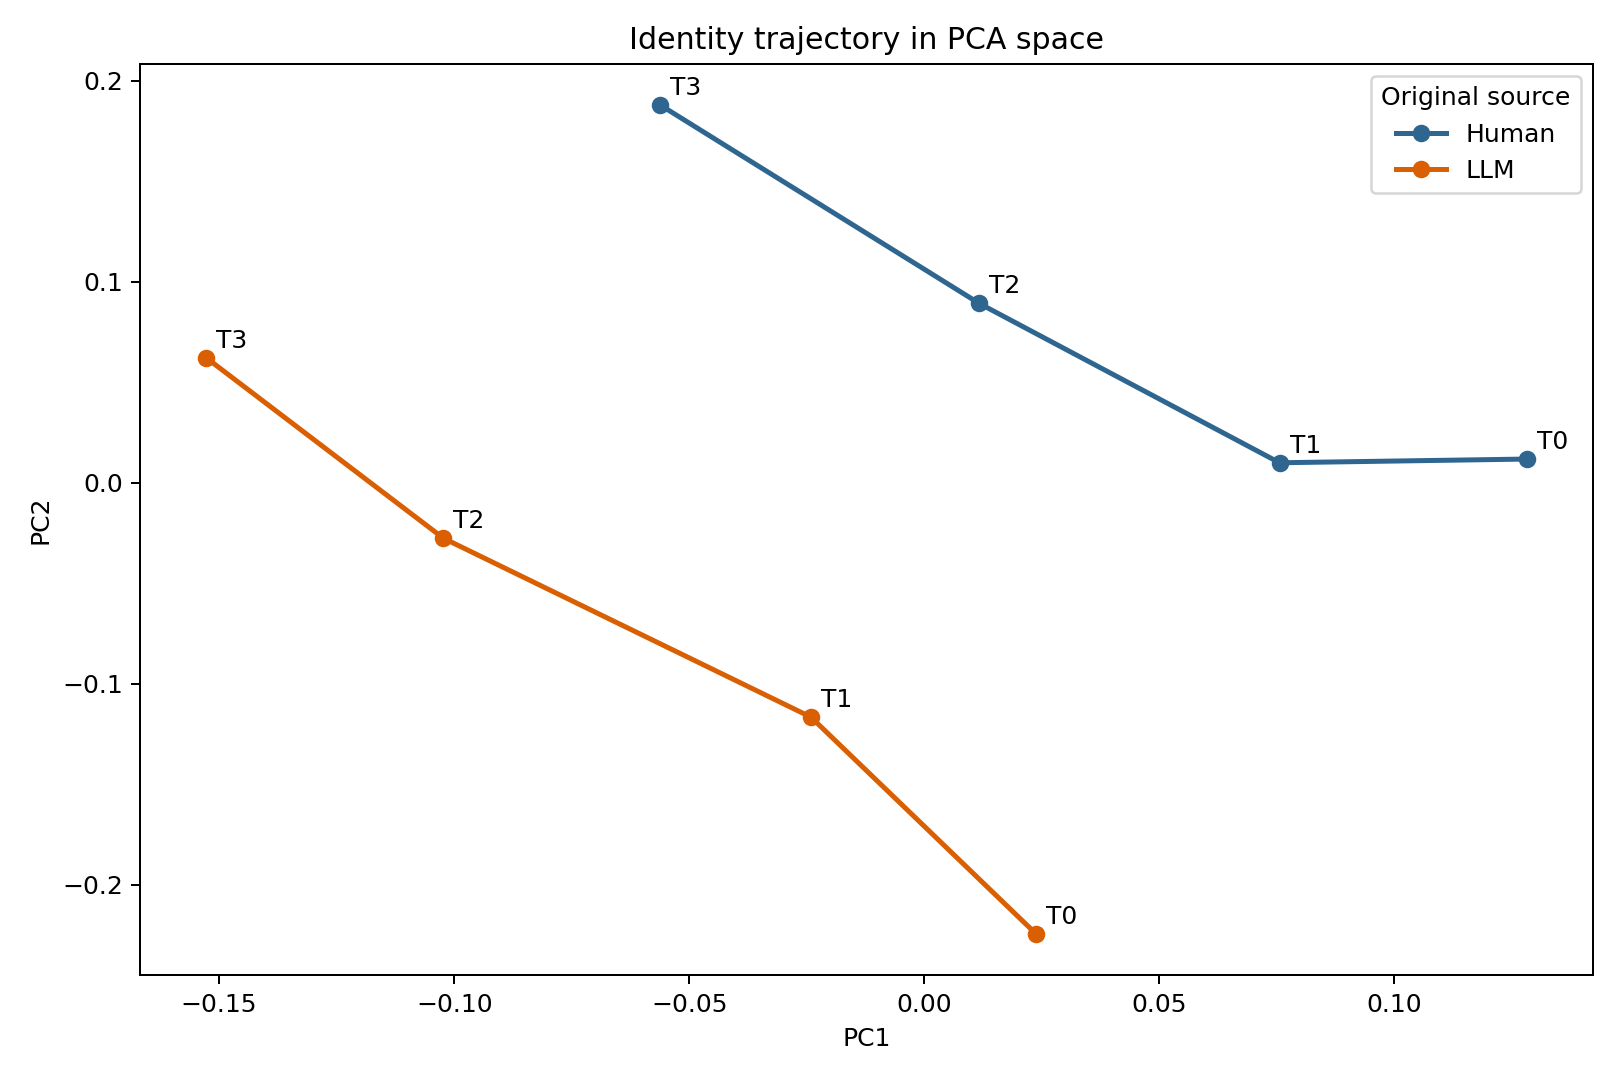

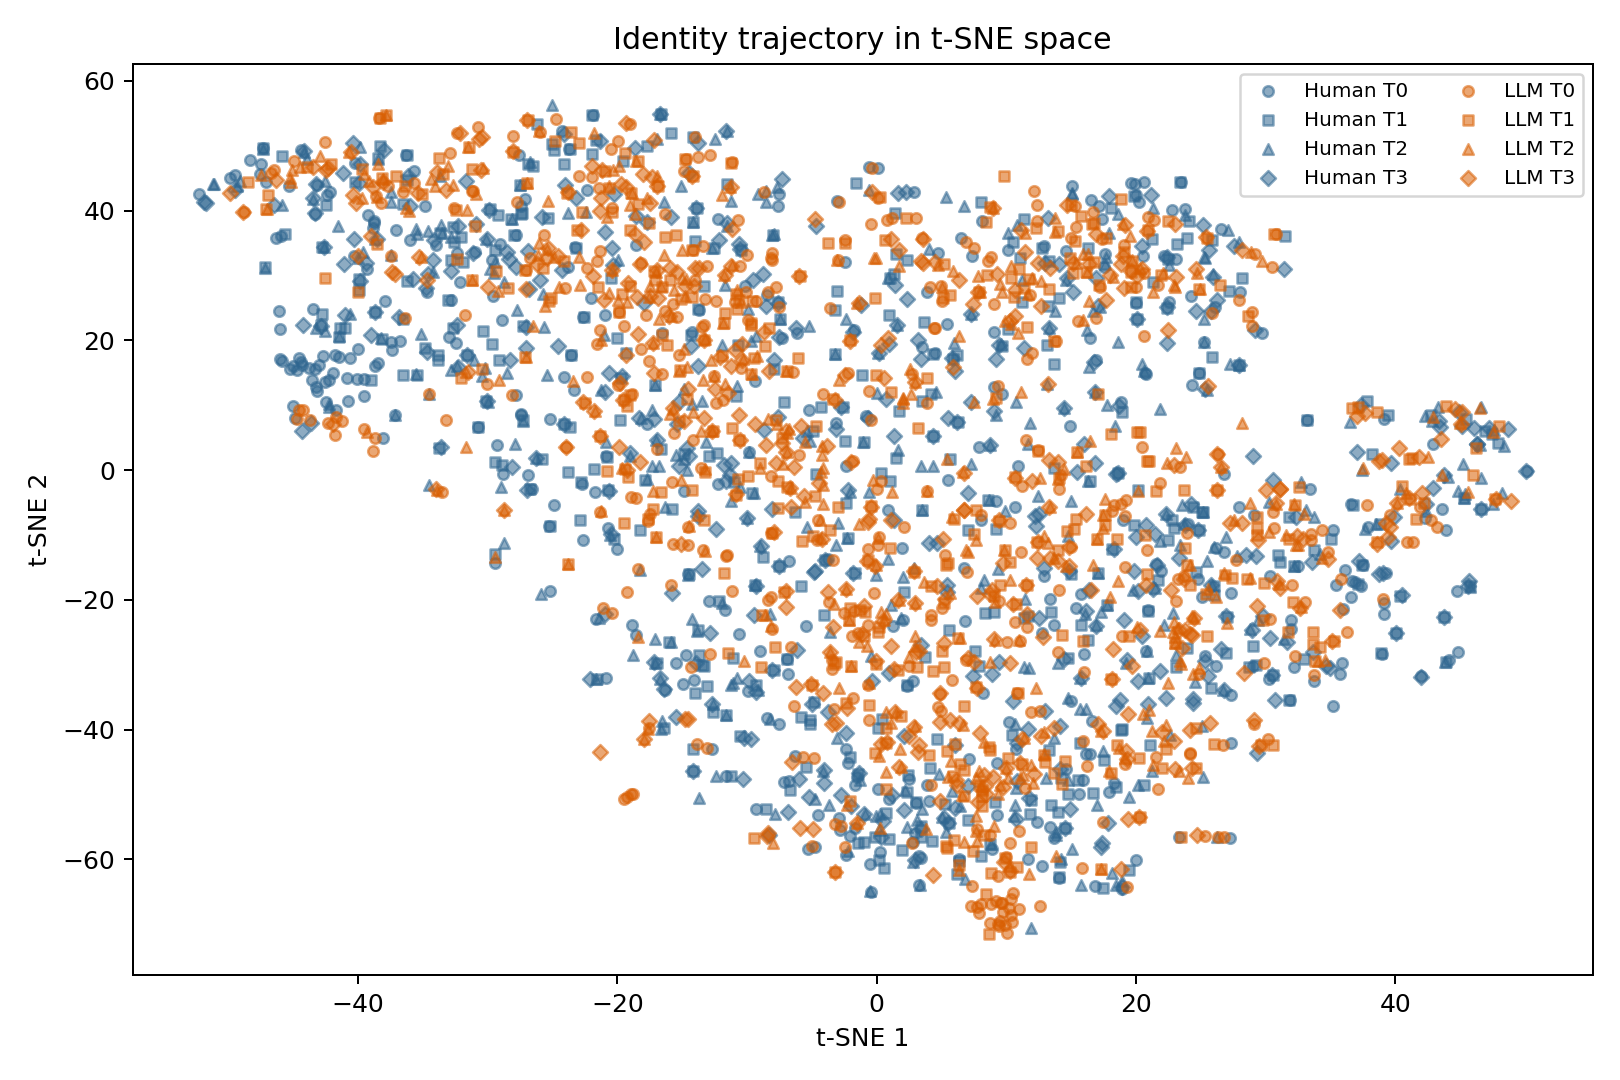

In [5]:
display(Image(filename=str(FIGURES_DIR / 'rq2_pca_identity_trajectory.png')))
display(Image(filename=str(FIGURES_DIR / 'rq2_tsne_identity_trajectory.png')))

## Initial interpretation

The PCA projection explains 34.36% of the standardized feature variance in its first two components. The dataset-balanced Human–LLM centroid distance decreases from 0.2752 at T0 to 0.1456 at T1, a 47.1% reduction, and reaches 0.1392 at T3, a 49.4% reduction from T0. Thus, the largest identity-space change occurs after the first paraphrasing step, while later steps show a smaller additional shift. This supports the attribution-decay pattern observed by the RQ2 classifier, but centroid distance is descriptive rather than an authorship accuracy measure. The t-SNE plot is exploratory: its axes are not directly comparable across runs, so the fixed random seed and balanced training-group sample are reported for reproducibility.